# CISC7204 Project: U.S. State Income vs. Poverty (2022–2023)

**Research question:** How large are the gaps in median household income and poverty rates across U.S. states, and has the gap between the highest- and lowest-income states widened between 2022 and 2023?

**Data (USDA ERS, place the two CSVs next to this notebook):**
- `PovertyEstimates.csv` — SAIPE 2023: median household income + poverty rate
- `EconomicConditions.csv` — unemployment & median household income, 2000–23

In [17]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

HERE = Path.cwd()
plt.rcParams["font.family"] = "Arial"

## 1. Read the raw USDA data

Both files are in long format (`FIPS_Code, area, Attribute, Value`). We keep state-level rows (FIPS ends in `000`, excluding the national row `0`) and pivot long → wide.

In [18]:
pov  = pd.read_csv(HERE / "Poverty2023.csv")
econ = pd.read_csv(HERE / "Unemployment2023.csv")

def states_wide(df, codecol):
    d = df[df["FIPS_Code"].astype(str).str.endswith("000") & (df["FIPS_Code"] != 0)].copy()
    wide = d.pivot_table(index=codecol, columns="Attribute", values="Value", aggfunc="first")
    return wide.rename_axis("abbr").reset_index()

pov_w = states_wide(pov, "Stabr")   # MEDHHINC_2023, PCTPOVALL_2023
eco_w = states_wide(econ, "State")  # Median_Household_Income_2022
print("poverty cols:", [c for c in pov_w.columns if "HINC" in c or "PCTPOV" in c])
print("econ cols example:", "Median_Household_Income_2022" in eco_w.columns)

poverty cols: ['MEDHHINC_2023', 'PCTPOV017_2023', 'PCTPOV04_2023', 'PCTPOV517_2023', 'PCTPOVALL_2023']
econ cols example: True


## 2. Merge the two sources by state abbreviation

In [19]:
df = pov_w[["abbr", "MEDHHINC_2023", "PCTPOVALL_2023"]].merge(
        eco_w[["abbr", "Median_Household_Income_2022"]], on="abbr"
    ).dropna()
df = df.rename(columns={"MEDHHINC_2023": "inc2023",
                        "Median_Household_Income_2022": "inc2022",
                        "PCTPOVALL_2023": "pov2023"})
print(f"States merged: {len(df)}")
df.head()

States merged: 51


Attribute,abbr,inc2023,pov2023,inc2022
0,AK,88696.0,10.5,88072.0
1,AL,62248.0,15.7,59703.0
2,AR,58748.0,15.4,55505.0
3,AZ,77158.0,12.6,74355.0
4,CA,95473.0,12.0,91517.0


## Figure 1 — Ranked bar chart of 2023 median household income

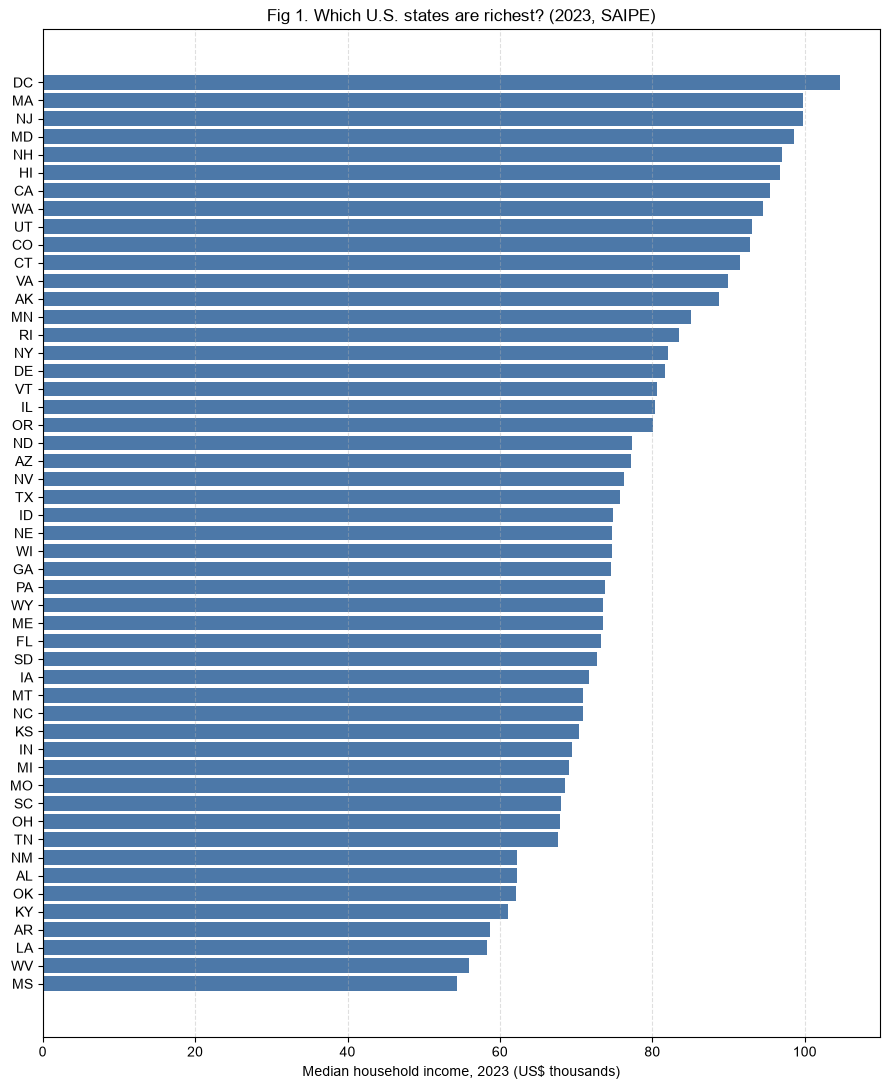

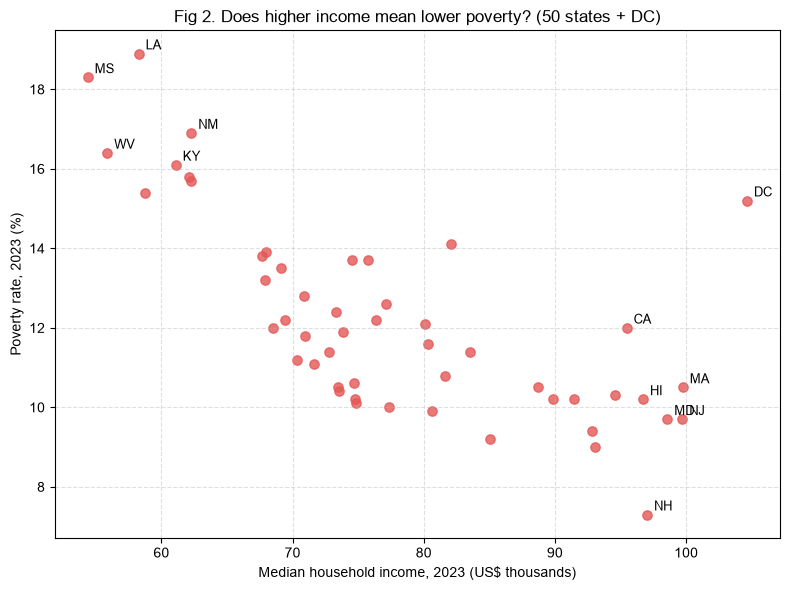

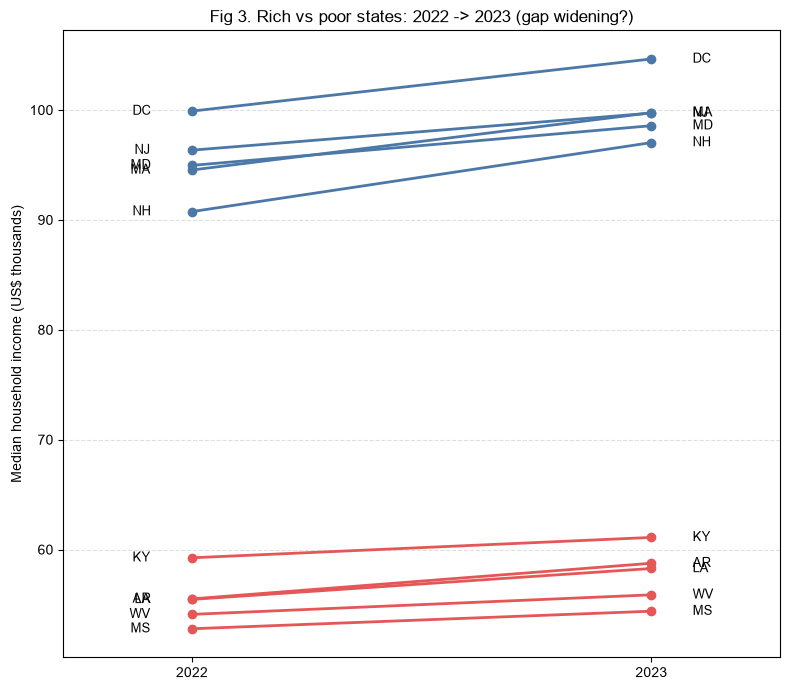

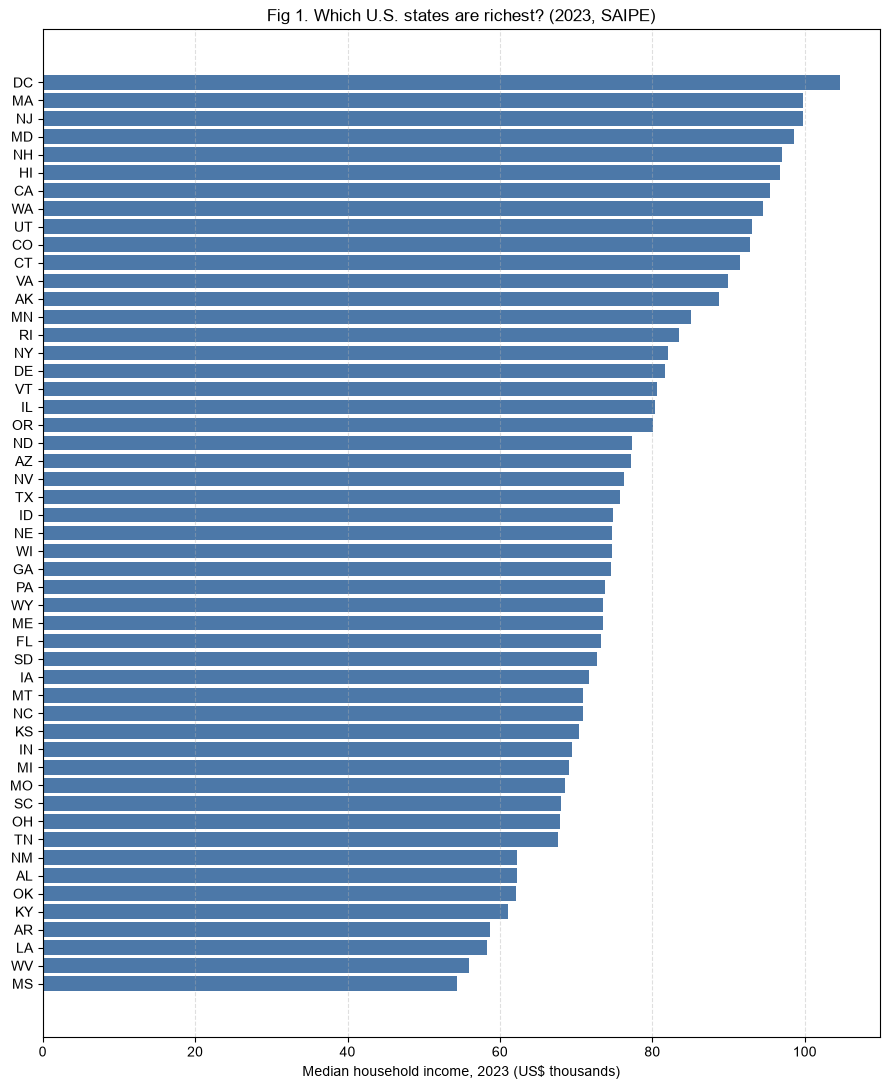

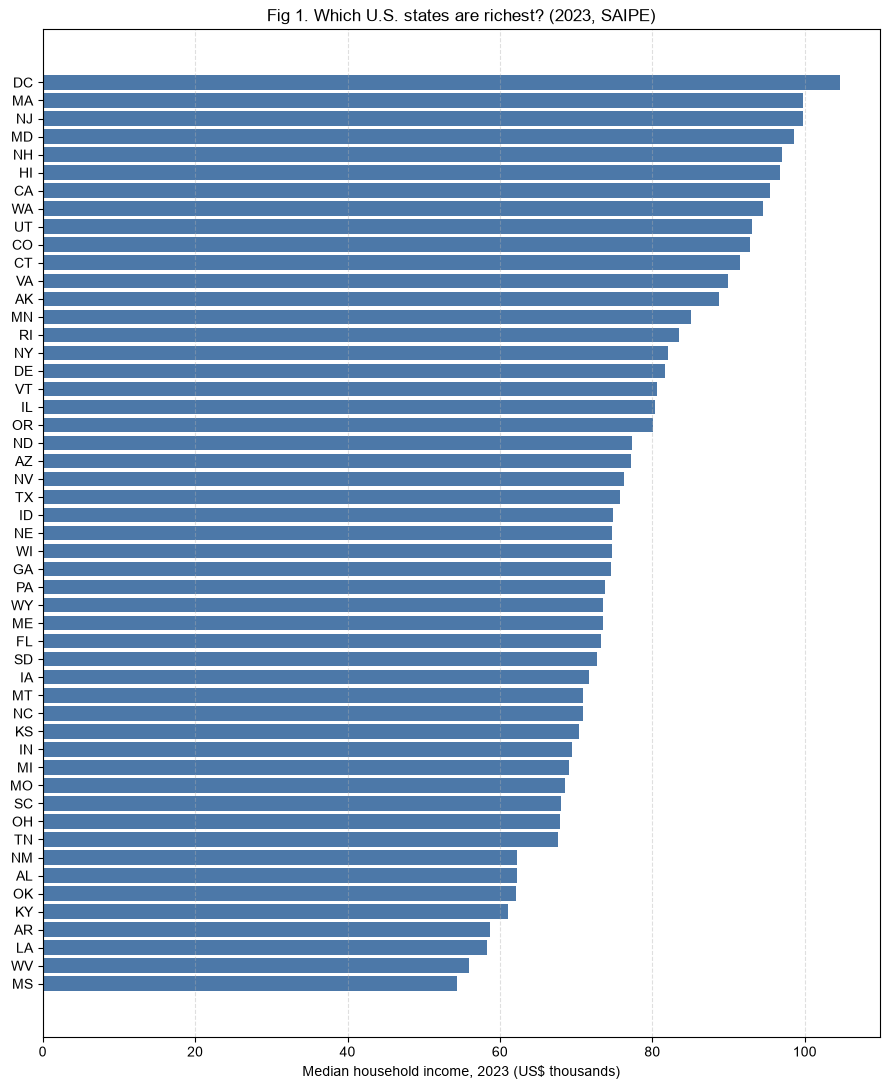

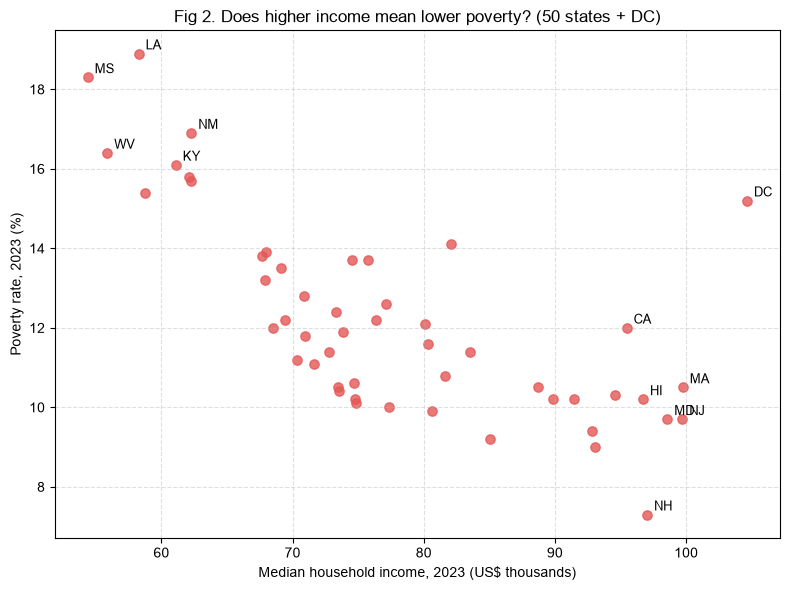

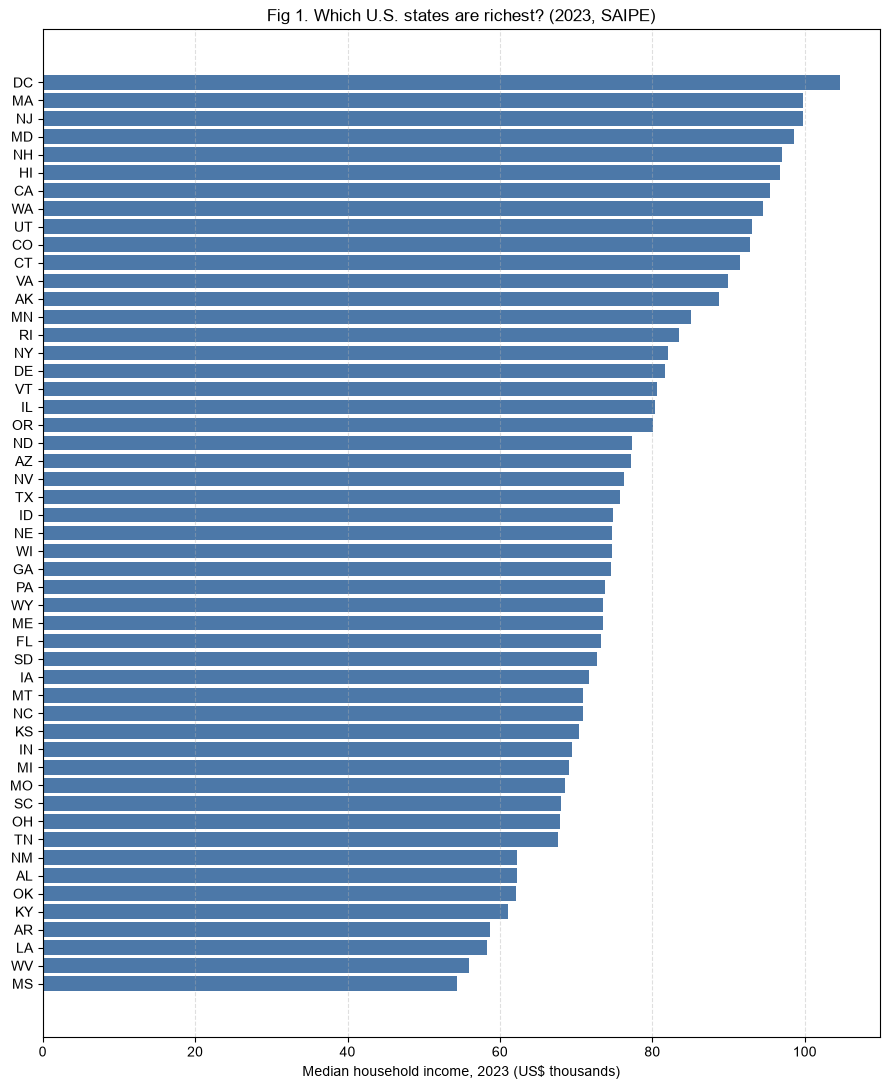

In [20]:
d1 = df.sort_values("inc2023", ascending=True)
fig, ax = plt.subplots(figsize=(9, 11))
ax.barh(d1["abbr"], d1["inc2023"]/1000, color="#4C78A8")
ax.set_xlabel("Median household income, 2023 (US$ thousands)")
ax.set_title("Fig 1. Which U.S. states are richest? (2023, SAIPE)")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout(); plt.savefig(HERE/"fig1_real.png", dpi=130); plt.show()

## Figure 2 — Income vs. poverty rate scatter

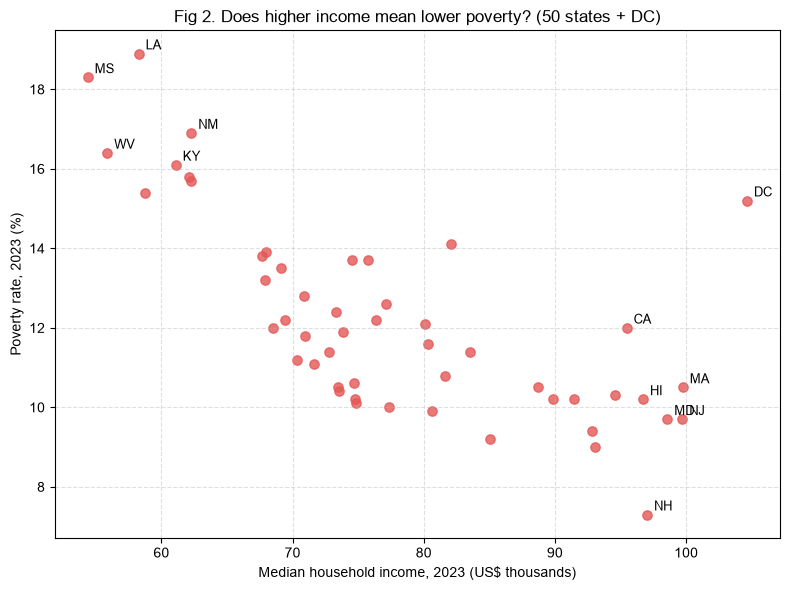

In [21]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(df["inc2023"]/1000, df["pov2023"], color="#E45756", s=45, alpha=0.8)
for _, r in df.iterrows():
    if r["pov2023"] > 16 or r["inc2023"] > 95000 or r["abbr"] == "DC":
        ax.annotate(r["abbr"], (r["inc2023"]/1000, r["pov2023"]),
                    fontsize=9, xytext=(5, 3), textcoords="offset points")
ax.set_xlabel("Median household income, 2023 (US$ thousands)")
ax.set_ylabel("Poverty rate, 2023 (%)")
ax.set_title("Fig 2. Does higher income mean lower poverty? (50 states + DC)")
ax.grid(linestyle="--", alpha=0.4)
plt.tight_layout(); plt.savefig(HERE/"fig2_real.png", dpi=130); plt.show()

## Figure 3 — Top-5 vs. bottom-5 states, 2022 → 2023 slope chart

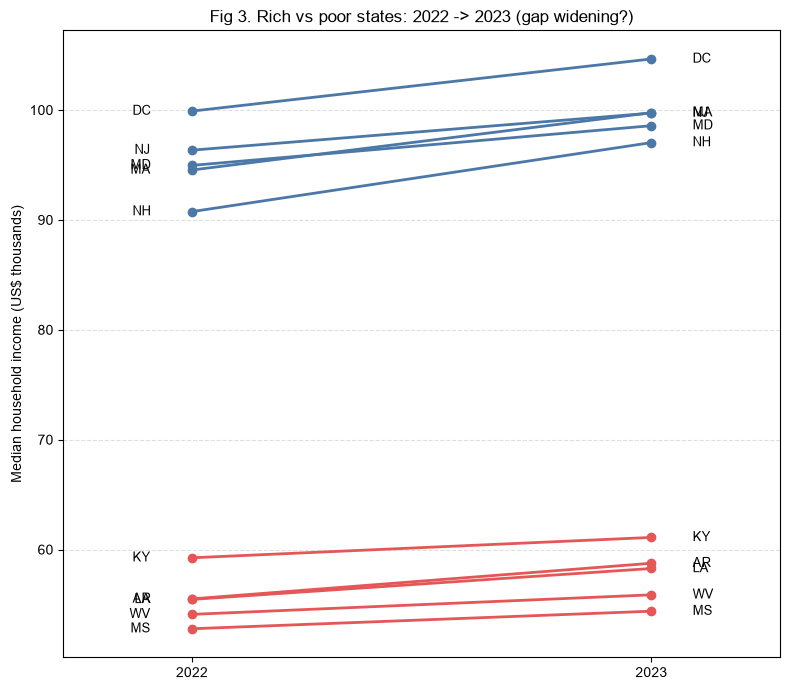

In [22]:
top5 = df.nlargest(5, "inc2023")
bot5 = df.nsmallest(5, "inc2023")
sel = pd.concat([top5, bot5])
fig, ax = plt.subplots(figsize=(8, 7))
for _, r in sel.iterrows():
    is_top = r["inc2023"] >= top5["inc2023"].min()
    c = "#4C78A8" if is_top else "#E45756"
    ax.plot([0, 1], [r["inc2022"]/1000, r["inc2023"]/1000], marker="o", color=c, linewidth=2.0)
    ax.text(-0.09, r["inc2022"]/1000, r["abbr"], ha="right", va="center", fontsize=9)
    ax.text(1.09, r["inc2023"]/1000, r["abbr"], ha="left", va="center", fontsize=9)
ax.set_xticks([0, 1]); ax.set_xticklabels(["2022", "2023"])
ax.set_ylabel("Median household income (US$ thousands)")
ax.set_title("Fig 3. Rich vs poor states: 2022 -> 2023 (gap widening?)")
ax.set_xlim(-0.28, 1.28); ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout(); plt.savefig(HERE/"fig3_real.png", dpi=130); plt.show()

## Key numbers for the written justification

In [23]:
gap22 = top5["inc2022"].mean() - bot5["inc2022"].mean()
gap23 = top5["inc2023"].mean() - bot5["inc2023"].mean()
print("top5:", top5["abbr"].tolist(), "| bottom5:", bot5["abbr"].tolist())
print(f"income-poverty correlation: r = {df['inc2023'].corr(df['pov2023']):.3f}")
print(f"rich-poor gap 2022: ${gap22/1000:.1f}k | 2023: ${gap23/1000:.1f}k")

top5: ['DC', 'MA', 'NJ', 'MD', 'NH'] | bottom5: ['MS', 'WV', 'LA', 'AR', 'KY']
income-poverty correlation: r = -0.692
rich-poor gap 2022: $39.9k | 2023: $42.3k
